In [1]:
import matplotlib.pyplot as plt
import numpy as np
from superfv.tools.stability_analysis.rk import compute_rk_amplification
from superfv.tools.stability_analysis.sd_advection import compute_solution_and_flux_point_coordinates

In [2]:
def plot_amplification_values(ax, p, k_values, cfl_values, scheme, rk, operator, coeff_D_lambda=None, **kwargs):
    data = []
    for cfl_val in cfl_values:
        coeff = dict(coeff_C=cfl_val, coeff_D=cfl_val if coeff_D_lambda is None else coeff_D_lambda(cfl_val))
        max_amplification = compute_rk_amplification(p, k_values, scheme=scheme, rk=rk, operator=operator, **coeff)
        data.append(max_amplification)
    y = np.array(data)

    ax.plot(cfl_values, y, **kwargs)

In [3]:
def compute_amplification_mesh(p, k_values, scheme, rk, operator, coeff_C_values, coeff_D_values):
    out = np.empty((len(coeff_D_values), len(coeff_C_values)))
    for i, coeff_D in enumerate(coeff_D_values):
        for j, coeff_C in enumerate(coeff_C_values):
            out[i, j] = compute_rk_amplification(p, k_values, scheme, rk, operator, coeff_C=coeff_C, coeff_D=coeff_D)
    return out

def compute_first_order_amplification_mesh(coeff_C_values, coeff_D_values):
    out = np.empty((len(coeff_D_values), len(coeff_C_values)))
    for i, coeff_D in enumerate(coeff_D_values):
        for j, coeff_C in enumerate(coeff_C_values):
            out[i, j] = coeff_C + 2 * coeff_D
    return out


In [4]:
def get_smallest_cell_rescale(p):
    _, fps = compute_solution_and_flux_point_coordinates(p)
    return (fps[1] - fps[0])

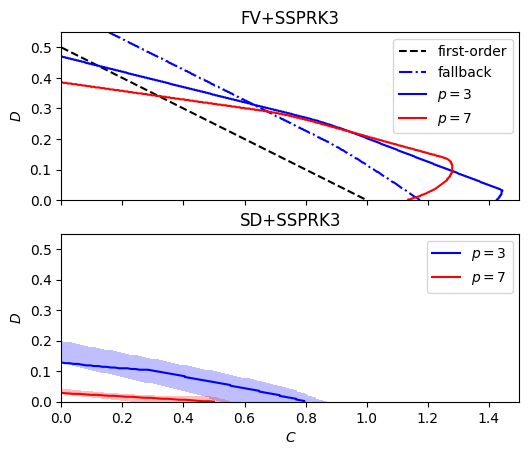

In [5]:
fig, axs = plt.subplots(2, 1, sharex=True, sharey=True)
axs[1].set_xlabel(r"$C$")
axs[0].set_xlim(0.0, 1.5)
axs[0].set_ylim(0.0, 0.55)
for ax in axs.flatten():
    ax.set_aspect("equal")
    ax.set_ylabel(r"$D$")

k_values = np.linspace(0.0, 2 * np.pi, 100)

axs[0].set_title("FV+SSPRK3")

# Stability boundary of first-order scheme
coeff_C_values = np.linspace(0.0, 1.5, 512)
coeff_D_values = np.linspace(0.0, 0.55, 256)
amplification = compute_first_order_amplification_mesh(coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='black', linestyles='--')

# Stability boundary of MUSCL fallback
amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue', linestyles='dashdot')

# Stability boundary of FV4
amplification = compute_amplification_mesh(3, k_values, "fv", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue')

# Stability boundary of FV8
amplification = compute_amplification_mesh(7, k_values, "fv", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='red')

legend_handles = [
    plt.Line2D([], [], color='black', linestyle='--', label="first-order"),
    plt.Line2D([], [], color='blue', linestyle='dashdot', label="fallback"),
    plt.Line2D([], [], color='blue', label=r"$p=3$"),
    plt.Line2D([], [], color='red', label=r"$p=7$"),
]
axs[0].legend(handles=legend_handles)

axs[1].set_title("SD+SSPRK3")

# # Stability boundary of MUSCL fallback on smallest cell (p=3)
# coeff_C_values = np.linspace(0.0, 0.6, 64)
# coeff_D_values = np.linspace(0.0, 0.2, 64)
# rescale = get_smallest_cell_rescale(3)
# amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
# axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue', linestyles='dashdot')

# # Stability boundary of MUSCL fallback on nonuniform mesh (p=3)
# coeff_C_values = np.linspace(0.0, 1.0, 64)
# coeff_D_values = np.linspace(0.0, 0.25, 64)
# amplification = compute_amplification_mesh(3, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
# axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-14], colors='blue', linestyles='dotted')

# # Stability boundary of MUSCL fallback on smallest cell (p=7)
# coeff_C_values = np.linspace(0.0, 0.3, 32)
# coeff_D_values = np.linspace(0.0, 0.05, 32)
# rescale = get_smallest_cell_rescale(7)
# amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
# axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='red', linestyles='dashdot')

# # Stability boundary of MUSCL fallback on nonuniform mesh (p=7)
# coeff_C_values = np.linspace(0.0, 1.0, 64)
# coeff_D_values = np.linspace(0.0, 1.0, 64)
# amplification = compute_amplification_mesh(7, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
# axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-14], colors='red', linestyles='dotted')

# Stability boundary of MUSCL fallback on smallest cell and nonuniform mesh (p=3)
coeff_C_values = np.linspace(0.0, 1.0, 64)
coeff_D_values = np.linspace(0.0, 0.25, 64)
rescale = get_smallest_cell_rescale(3)
amplification_nonuniform = compute_amplification_mesh(3, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
amplification = np.where(amplification_nonuniform > 1.0 + 1e-14, 0.0, 1.0)
amplification_uniform = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
amplification = np.where(amplification_uniform < 1.0 + 1e-14, 0.0, amplification)
axs[1].contourf(coeff_C_values, coeff_D_values, amplification, levels=[0.5, 1.5], colors='blue', alpha=0.25)

# Stability boundary of MUSCL fallback on smallest cell and nonuniform mesh (p=3)
coeff_C_values = np.linspace(0.0, 0.6, 128)
coeff_D_values = np.linspace(0.0, 0.1, 64)
rescale = get_smallest_cell_rescale(7)
amplification_nonuniform = compute_amplification_mesh(7, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
amplification = np.where(amplification_nonuniform > 1.0 + 1e-14, 0.0, 1.0)
amplification_uniform = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
amplification = np.where(amplification_uniform < 1.0 + 1e-14, 0.0, amplification)
axs[1].contourf(coeff_C_values, coeff_D_values, amplification, levels=[0.5, 1.5], colors='red', alpha=0.25)

# Stability boundary of SD4
coeff_C_values = np.linspace(0.0, 0.85, 64)
coeff_D_values = np.linspace(0.0, 0.15, 64)
amplification = compute_amplification_mesh(3, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='blue')

# Stability boundary of SD8
coeff_C_values = np.linspace(0.0, 0.6, 32)
coeff_D_values = np.linspace(0.0, 0.05, 32)
amplification = compute_amplification_mesh(7, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='red')

legend_handles = [
    plt.Line2D([], [], color='blue', label=r"$p=3$"),
    # plt.Line2D([], [], color='blue', label=r"$p=3$ fallback $h_{\min}$", linestyle='dashdot'),
    # plt.Line2D([], [], color='blue', label=r"$p=3$ fallback", linestyle='dotted'),
    plt.Line2D([], [], color='red', label=r"$p=7$"),
    # plt.Line2D([], [], color='red', label=r"$p=7$ fallback $h_{\min}$", linestyle='dashdot'),
    # plt.Line2D([], [], color='red', label=r"$p=7$ fallback", linestyle='dotted'),
]
axs[1].legend(handles=legend_handles)

fig.savefig("../out/stabililty.pdf")

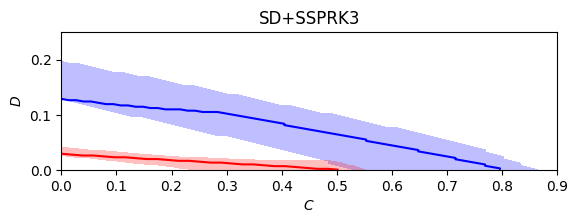

In [8]:
fig, ax = plt.subplots()
ax.set_xlabel(r"$C$")
ax.set_xlim(0.0, 0.9)
ax.set_ylim(0.0, 0.25)
ax.set_aspect("equal")
ax.set_ylabel(r"$D$")

k_values = np.linspace(0.0, 2 * np.pi, 100)

ax.set_title("SD+SSPRK3")

# Stability boundary of MUSCL fallback on smallest cell and nonuniform mesh (p=3)
coeff_C_values = np.linspace(0.0, 1.0, 64)
coeff_D_values = np.linspace(0.0, 0.25, 64)
rescale = get_smallest_cell_rescale(3)
amplification_nonuniform = compute_amplification_mesh(3, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
amplification = np.where(amplification_nonuniform > 1.0 + 1e-14, 0.0, 1.0)
amplification_uniform = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
amplification = np.where(amplification_uniform < 1.0 + 1e-14, 0.0, amplification)
ax.contourf(coeff_C_values, coeff_D_values, amplification, levels=[0.5, 1.5], colors='blue', alpha=0.25)

# Stability boundary of MUSCL fallback on smallest cell and nonuniform mesh (p=3)
coeff_C_values = np.linspace(0.0, 0.6, 128)
coeff_D_values = np.linspace(0.0, 0.1, 64)
rescale = get_smallest_cell_rescale(7)
amplification_nonuniform = compute_amplification_mesh(7, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
amplification = np.where(amplification_nonuniform > 1.0 + 1e-14, 0.0, 1.0)
amplification_uniform = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
amplification = np.where(amplification_uniform < 1.0 + 1e-14, 0.0, amplification)
ax.contourf(coeff_C_values, coeff_D_values, amplification, levels=[0.5, 1.5], colors='red', alpha=0.25)

# Stability boundary of SD4
coeff_C_values = np.linspace(0.0, 0.85, 64)
coeff_D_values = np.linspace(0.0, 0.15, 64)
amplification = compute_amplification_mesh(3, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
ax.contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='blue')

# Stability boundary of SD8
coeff_C_values = np.linspace(0.0, 0.6, 32)
coeff_D_values = np.linspace(0.0, 0.05, 32)
amplification = compute_amplification_mesh(7, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
ax.contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='red')

fig.savefig("../out/stabililty_sd_zoom.pdf")